# Refine the detector clocks

This step uses **only notebook 04's fitting anchors** to build a local clock map.
It checks the map on new sections that do not overlap 04's scheduled fitting or
validation windows. The map changes smoothly in straight segments between anchors.

This is a relative-clock correction, separate from the radiation-profile GAM.
It does not align the logger, establish UTC time, or identify physical particles.
Source timestamps remain intact. Times outside the anchor span are flagged and receive no extrapolated correction.

In [1]:
from pathlib import Path
import importlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/'src/refine_clock_maps.py').is_file()),None)
if ROOT is None:
    raise FileNotFoundError('Extract this update into the repository first.')
sys.path.insert(0,str(ROOT/'src'))
import refine_clock_maps
importlib.reload(refine_clock_maps)
print('Repository:',ROOT)

Repository: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning


In [2]:
RUN_ID='ground_run_01'  # Or 'ground_run_01'. Each recording uses its own 04 anchors.
BASE_ALIGNMENT_DIR=None  # Set a specific 04 output Path to pin a repeatable source run.

if RUN_ID=='ground_run_01':
    DETECTOR_FILES={k:ROOT/'raw'/RUN_ID/f'{k}.txt' for k in ['top','mid','bot']}
    FRESH_CENTERS_HOURS=list(np.arange(3.5,193.0,12.0))+[190.0]
elif RUN_ID=='2026-05-31':
    def resolve_source(value):
        path=Path(value)
        return (path if path.is_absolute() else ROOT/path).resolve()
    DETECTOR_FILES={}
    for device in ['left','middle','right']:
        path=ROOT/'configs'/f'{RUN_ID}_{device}.json'
        cfg=json.loads(path.read_text(encoding='utf-8'))
        if (cfg['flight_id'],cfg['detector_id'])!=(RUN_ID,device):
            raise ValueError(f'Configuration identity mismatch: {path}')
        DETECTOR_FILES[device]=resolve_source(cfg['detector_file'])
    FRESH_CENTERS_HOURS=[1.0,2.0,3.0,5.0,7.0,9.0]
else:
    raise ValueError('Review the protocol before adding another recording.')

if BASE_ALIGNMENT_DIR is None:
    BASE_ALIGNMENT_DIR=refine_clock_maps.latest_alignment(ROOT,RUN_ID)
else:
    BASE_ALIGNMENT_DIR=Path(BASE_ALIGNMENT_DIR)
    if not BASE_ALIGNMENT_DIR.is_absolute():
        BASE_ALIGNMENT_DIR=ROOT/BASE_ALIGNMENT_DIR
for path in DETECTOR_FILES.values():
    if not path.is_file():raise FileNotFoundError(path)
print('04 anchor source:',BASE_ALIGNMENT_DIR)
print('Fresh window centers [reference-clock hours]:',FRESH_CENTERS_HOURS)

04 anchor source: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\results\ground_run_01\20261116T060620364972Z_clock_alignment
Fresh window centers [reference-clock hours]: [np.float64(3.5), np.float64(15.5), np.float64(27.5), np.float64(39.5), np.float64(51.5), np.float64(63.5), np.float64(75.5), np.float64(87.5), np.float64(99.5), np.float64(111.5), np.float64(123.5), np.float64(135.5), np.float64(147.5), np.float64(159.5), np.float64(171.5), np.float64(183.5), 190.0]


## Apply and check the local map

Only 04 fitting rows define the knots. Neither the old validation rows nor these
fresh rows become fitting anchors. The 04 constant-drift model and the local map
are compared on exactly the same fresh sections.

The full timestamp arrays are mapped in memory to check ordering and domain coverage.
A small sample is exported for review. The original files are not rewritten.

In [3]:
report,fresh_validation,RUN_DIR=refine_clock_maps.run(
    ROOT,RUN_ID,DETECTOR_FILES,BASE_ALIGNMENT_DIR,
    np.asarray(FRESH_CENTERS_HOURS)*3600,
)
print('Outputs:',RUN_DIR)
display(pd.DataFrame(report['metrics']))
display(pd.DataFrame.from_dict(report['mapping_coverage'],orient='index'))
print('Source hashes unchanged:',report['source_hashes_unchanged'])
print('Logger aligned:',report['logger_aligned'])
print('UTC verified:',report['utc_verified'])

Outputs: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\results\ground_run_01\20261116T063332368751Z_clock_refinement


,device,fresh_windows,supported_fresh_windows,all_fresh_signals_supported,affine_fresh_mae_ms,local_fresh_mae_ms,local_fresh_max_abs_error_ms
0,mid,17,17,True,3.630451,0.279557,0.799217
1,bot,17,17,True,3.184787,0.280824,0.717461


,source_events,events_inside_anchor_span,events_outside_anchor_span,outside_events_preserved_in_original
top,3909912,3874923,34989,True
mid,4085008,4048286,36722,True
bot,3678007,3645201,32806,True


Source hashes unchanged: True
Logger aligned: False
UTC verified: False


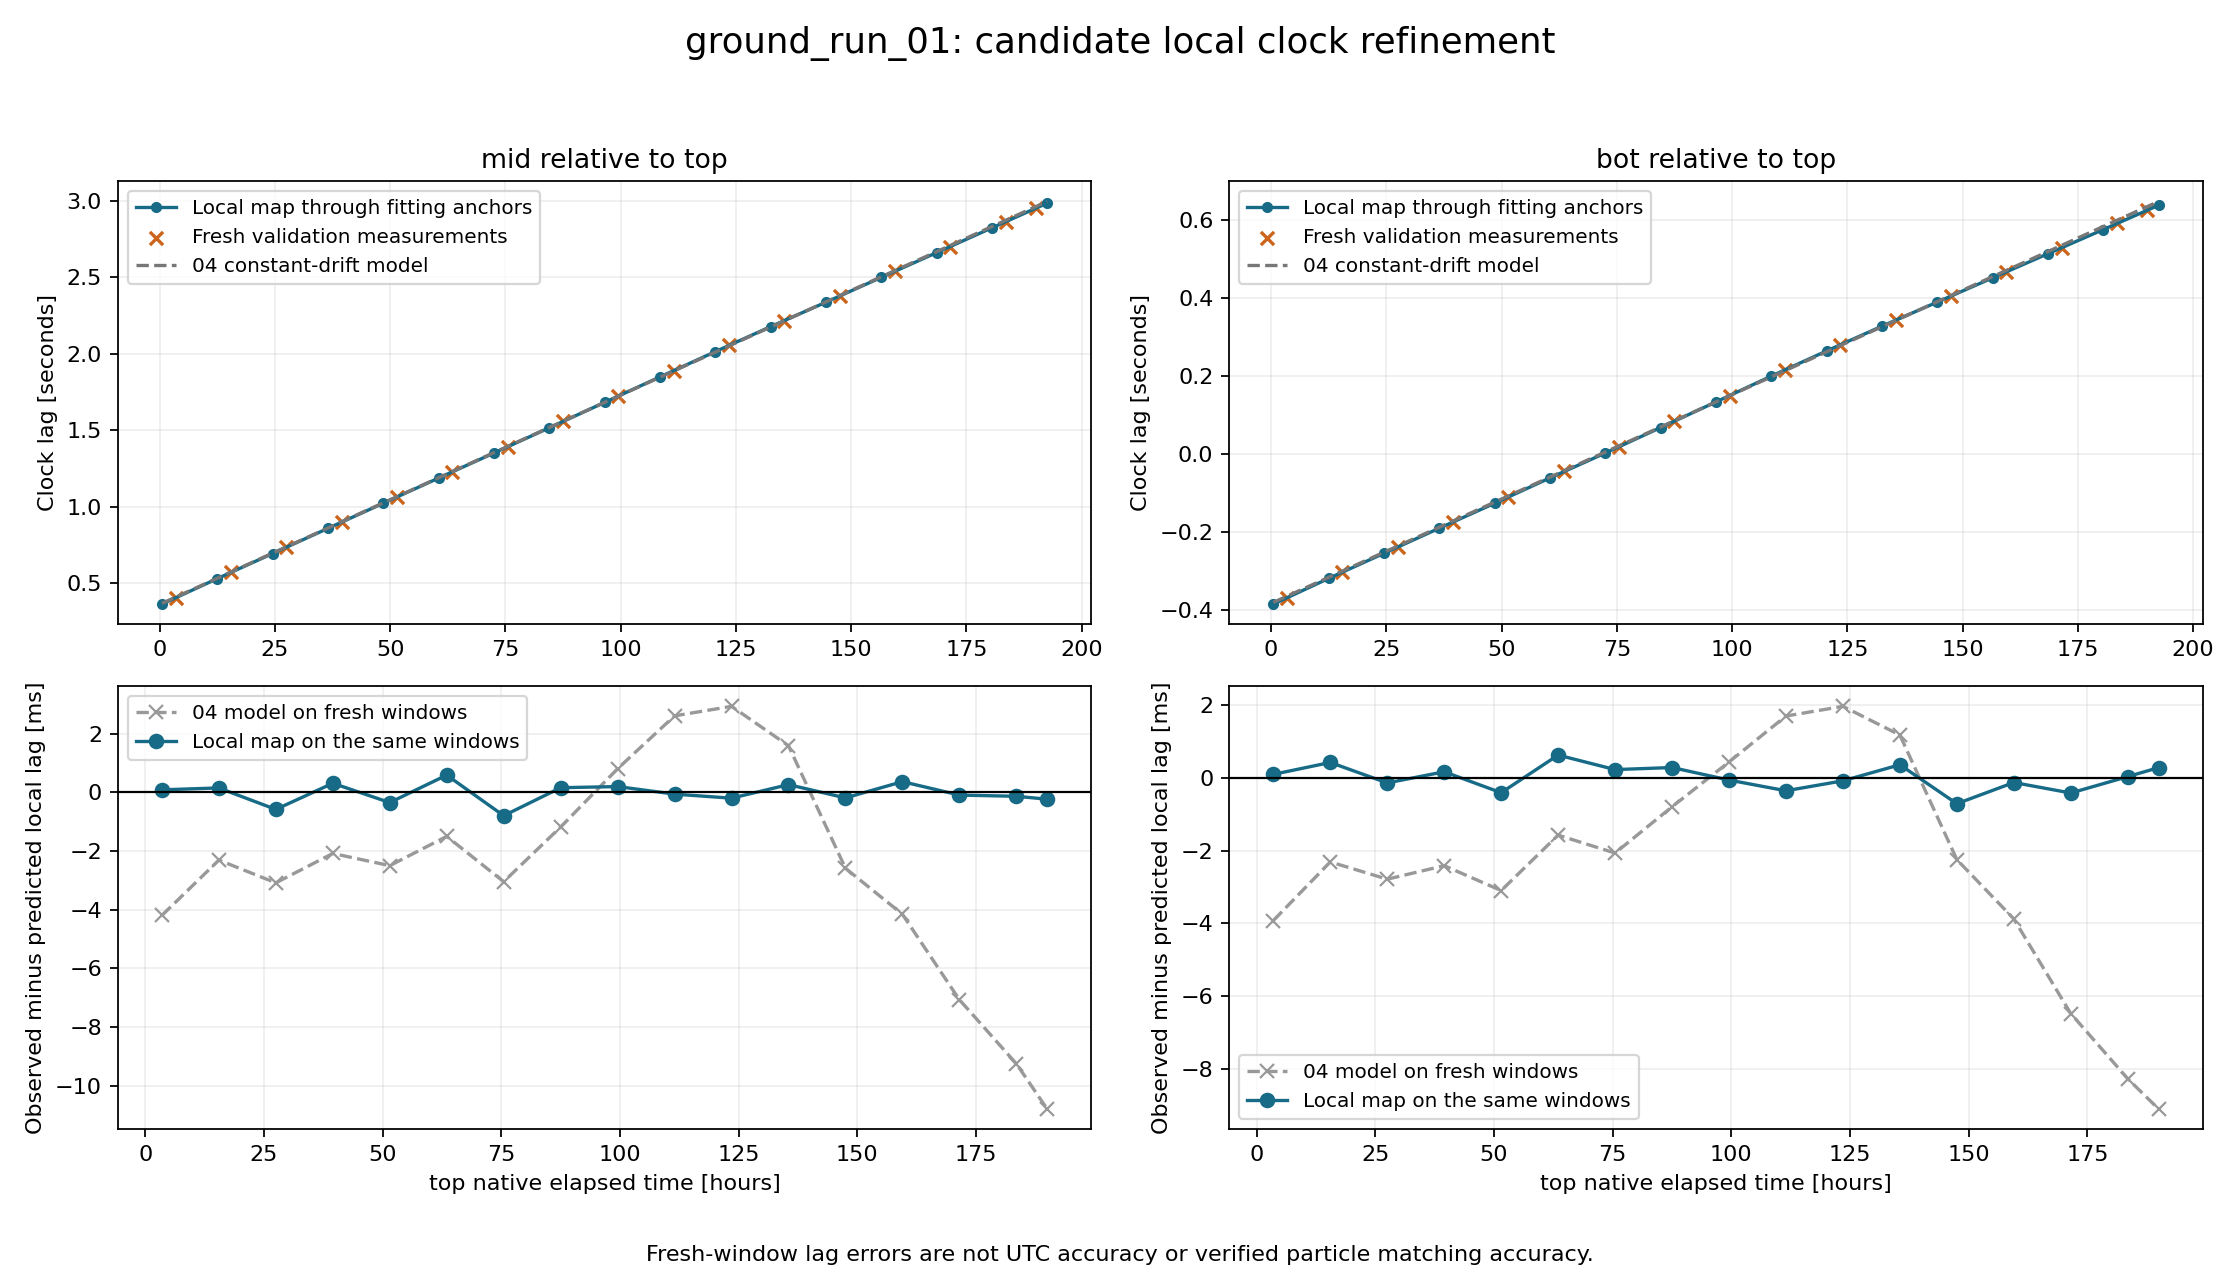

,device,source_record_1based,event_time_native_s,time_reference_candidate_s,inside_anchor_span
0,top,1,0.231435,NaN,False
1,top,13077,2320.861744,2320.861744,True
2,top,26154,4669.278891,4669.278891,True
3,top,39230,7042.083202,7042.083202,True
4,top,52307,9379.545372,9379.545372,True
5,top,65384,11730.132775,11730.132775,True
6,top,78460,14068.184133,14068.184133,True
7,top,91537,16397.134782,16397.134782,True
8,top,104614,18707.917546,18707.917546,True
9,top,117690,21062.899171,21062.899171,True


In [4]:
display(Image(filename=str(RUN_DIR/'clock_refinement.png')))
display(pd.read_csv(RUN_DIR/'corrected_clock_sample.csv').head(12))

## What the result establishes

- `refinement_report.json` saves the candidate local-map knots, source hashes, metrics, and limits.
- `fresh_window_validation.csv` saves the independent timing estimates and signal checks.
- `refinement_metrics.csv` compares both methods on the same fresh windows.
- `corrected_clock_sample.csv` shows native versus candidate reference times. Blank corrected times
  indicate samples outside the anchor span; those events remain in the original data.
- `clock_refinement.png` shows the anchor curve and remaining fresh-window errors.

The scores measure **local timing-peak prediction**, not individual-event accuracy or UTC accuracy.
An inside-anchor-span flag is not a precision guarantee at every instant. Check the required
timing tolerance and physical coincidence behavior before treating events as matched particles.
The logger and its recording coverage remain unresolved. These maps must not be transferred to another run.

To use a saved map later: `refine_clock_maps.map_times(native_times, report['models'][device])`
returns candidate reference times plus the domain flag, without changing the input array.